# Segment 4 · Robot learning with a surgical VLA and a world model
**CoRL 2026 Tutorial — Robot Learning on the Path to Surgical Autonomy** · minutes 45–60

In Segment 3 a small policy (ACT) learned SutureBot from scratch. Here we ask what large pretrained models add:

| | ACT (Segment 3) | **GR00T-H-N1.7** (VLA) | **Cosmos-H-Dreams** (world model) |
|---|---|---|---|
| Input | images + robot state | images + **language instruction** | one frame + a sequence of actions |
| Output | action chunk | action chunk (50 steps @ 30 Hz ≈ 1.7 s) | **video** of what those actions would do |
| Pretraining | none | Open-H: 20 robot platforms, 770 h | Open-H, 9 embodiments |
| Role today | baseline | the policy | a "simulator" to look at actions |

**How this notebook works**
- ▶ **Main thread** — the cells we run together. They call a shared GPU server, so this notebook runs on a free CPU Colab.
- 🧪 **Explore on your own** — the section at the bottom. Every cell there is independent; run any of them whenever you like.
- If the server is unreachable, set `BACKEND = "cache"` and every main-thread cell replays pre-computed results.

Models: [GR00T-H-N1.7](https://huggingface.co/nvidia/GR00T-H-N1.7) · [Cosmos-H-Dreams](https://huggingface.co/nvidia/Cosmos-H-Dreams) · Data: [Open-H-Embodiment / SutureBot](https://huggingface.co/datasets/nvidia/PhysicalAI-Robotics-Open-H-Embodiment)

## 📖 Background · Meet the two models
*Reading material only, nothing to run. Skim it now, or come back to it after the session.*

### GR00T-H-N1.7: a vision-language-action (VLA) policy
**What it is.** NVIDIA's surgical robot foundation model (the "H" stands for healthcare). It looks at camera images, reads a short text instruction, and outputs the next robot motions. It has about 3 B parameters, was pretrained on the Open-H-Embodiment dataset, and the checkpoint we use has been fine-tuned on data that includes SutureBot.

**How it works.** Two parts, trained together:
1. **Vision-language backbone** (Cosmos-Reason2-2B). It turns the camera images and the instruction into a set of features that describe the scene and the goal.
2. **Action head**, a diffusion transformer trained with *flow matching*. It starts from random noise and refines it over a few steps into a full **action chunk**, using the backbone's features as a guide.

Predicting a whole chunk (50 steps ≈ 1.7 s) at once, instead of one step at a time, gives smoother motion and fewer model calls. ACT from Segment 3 uses the same idea.

**One model, many robots.** An **embodiment tag** tells the model which robot it is driving, so it knows which cameras to expect and how to read and write that robot's states and actions. We use `jhu_imerse_dvrk` (the dVRK-Si setup used for SutureBot):

| | |
|---|---|
| Cameras | `endoscope_left`, `wrist_left`, `wrist_right` |
| Instruction | the subtask: *needle pickup*, *needle throw* or *knot tying* |
| Robot state | 16 values, but trained with 100 % dropout for this robot, so it is ignored |
| Output | 50 steps × 16 values at 30 Hz. Per arm (PSM1, PSM2): position xyz (m), orientation quaternion (xyzw), jaw angle (rad) |

Inside, the model predicts motion *relative* to the current pose (xyz plus a 6-D rotation). It converts back to absolute values in the robot's own units before returning them.

**Why it matters.** In the Open-H report, GR00T-H matched ACT's SutureBot success rate with only a third of the training data. With all the data it reached ≈73 % against ACT's ≈50 %, and it was the only policy to complete end-to-end suturing (25 %).

---

### Cosmos-H-Dreams: an action-conditioned world model
**What it is.** A video model that answers one question: *"If the robot made these motions from this exact scene, what would the endoscope see?"* Give it one real frame and a sequence of robot actions, and it generates the video that should follow.

**How it works.**
- It is a fast, **distilled** "student" of Cosmos-H-Surgical-Simulator, which is built on Cosmos-Predict2.5-2B. Distillation trains a small, quick model to copy a large, slow one. On our server one 72-frame rollout takes a few seconds.
- It generates **autoregressively in blocks**: context frame (288 × 512) + the next actions → 12 new frames (~1.2 s at 10 fps). The newest frames then become the context for the next block. Small errors can build up from block to block, so we stop after 6 blocks (72 frames, ~7 s), the same length used in the Open-H report.
- It only renders the **left endoscope view**. It does not render the wrist cameras.

**Action format.** Cosmos-H-Dreams uses one shared 44-D action space for all the robots it supports. The dVRK uses 20 of those dimensions: for each arm, xyz (3) + 6-D rotation (6) + jaw (1). These are measured *relative to the robot's pose at the start frame* and normalized. Our server converts any absolute 16-D, 30 Hz action array (from GR00T-H, the recording, ACT or your own policy) into this format and keeps every 3rd step to match 10 fps. That is why any policy's output can be "dreamed".

**What it's good for.**
- **Looking at a policy's actions without a robot.** Action curves are hard to read. A video shows whether the needle actually moves where it should.
- **Testing a policy safely.** Feed the generated frames back to the policy and repeat (closed loop). NVIDIA used this approach (Cosmos-Surg-dVRK) to screen GR00T-H checkpoints; see Explore F.

**What to watch out for.** It is a learned model, not a physics engine. It can blur tissue, lose track of the thread, or show physically impossible results. That is why every comparison below also rolls out the **recorded actions**: whatever gap remains between that rollout and the real video is the world model's own error. On our held-out clips, recorded-action rollouts score about L1 0.02 / SSIM 0.85 against the real video, compared with about 0.04 / 0.77 for a frozen first frame.

---

### How they fit together today
```
 real frame + instruction ──► GR00T-H-N1.7 ──► 50-step action chunk ──┐
                                                                      ├──► Cosmos-H-Dreams ──► predicted video ──► compare with real video
 recorded actions (reference) ────────────────────────────────────────┘                                            (L1, SSIM)
```
- **GR00T-H** is scored *open loop* against the recorded actions (section 3): how close are its motions to the surgeon's?
- **Cosmos-H-Dreams** turns those motions into video (section 4): what would they *do* to the scene?

**Quick glossary**
- **Open loop:** the policy always sees the real recorded scene, so its mistakes never affect what it sees next. **Closed loop:** it sees the results of its own actions, so mistakes can build up.
- **Action chunk:** a block of future actions predicted in one call.
- **PSM:** Patient Side Manipulator, one of the dVRK's instrument arms (PSM1 and PSM2).
- **L1 / SSIM:** per-frame pixel error (lower is better) and structural similarity (higher is better) between generated and real video.

## ▶ 0 · Setup (≈1 min)

In [1]:
#@title Connect to the tutorial server { display-mode: "form" }
API_URL = "https://corl-seg4-1ydgfxbcn.gobrev.dev"   #@param {type:"string"}
API_KEY = ""                          #@param {type:"string"}
BACKEND = "api"                       #@param ["api", "cache"]
CACHE_URL = "https://huggingface.co/datasets/kdb6df/corl2026-seg4-cache/resolve/main/seg4_bundle_{episode}.zip"  #@param {type:"string"}
EPISODE = 0                           #@param [0, 1441, 1442, 1443, 1444, 1445, 1446, 1447, 1448, 1449, 1450, 1451]
FRAME = -1                            #@param {type:"integer"}
# EPISODE 0 = the demo clip (1441). 1441-1444 are needle throws, 1445-1451 knot tying; all are held out
# from both models and pre-computed. FRAME -1 = that clip's pre-computed start frame (returns instantly).

!pip -q install scikit-image imageio[ffmpeg] av huggingface_hub pyarrow jinja2 > /dev/null

import json, time, io, base64, os, numpy as np, pandas as pd, requests, matplotlib.pyplot as plt
from IPython.display import HTML, display
H = {"X-API-Key": API_KEY}

def _get(path):  return requests.get(API_URL + path, headers=H, timeout=60)
def _post(path, j, timeout=120):
    r = requests.post(API_URL + path, json=j, headers=H, timeout=timeout); r.raise_for_status(); return r.json()

if BACKEND == "api":
    try:
        h = requests.get(API_URL + "/health", timeout=10).json()
        print("✅ server up:", h["model"], "| episodes:", h["episodes"], "| cosmos queue:", h["cosmos_queue"])
        if EPISODE == 0: EPISODE = h["episodes"][0]
        if FRAME < 0: FRAME = int(h.get("start_frames", {}).get(str(EPISODE), 0))
    except Exception as e:
        print("⚠️ server unreachable -> switching to cached results.", e); BACKEND = "cache"

BUNDLE = None
if BACKEND == "cache":
    import urllib.request, zipfile
    if EPISODE == 0: EPISODE = 1441
    urllib.request.urlretrieve(CACHE_URL.format(episode=EPISODE), "bundle.zip")
    import shutil; shutil.rmtree("bundle", ignore_errors=True); zipfile.ZipFile("bundle.zip").extractall("bundle")
    BUNDLE = json.load(open("bundle/bundle.json")); EPISODE, FRAME = BUNDLE["episode"], BUNDLE["frame"]
print("backend:", BACKEND, "| episode:", EPISODE, "| start frame:", FRAME)

✅ server up: nvidia/GR00T-H-N1.7 | episodes: [1441, 1442, 1443, 1444, 1445, 1446, 1447, 1448, 1449, 1450, 1451] | cosmos queue: 0
backend: api | episode: 1441 | start frame: 345


## ▶ 1 · The clip (≈1.5 min)
One **held-out test episode** from SutureBot (dVRK-Si, JHU). Neither model saw it in training. The default, 1441, is the same episode as Segment 3, so the ACT numbers are directly comparable. Want another? Pick any of 1441–1451 in the Setup cell and re-run from there: every one is pre-computed.

In [2]:
#@title Download just this episode (parquet + endoscope video) { display-mode: "form" }
from huggingface_hub import hf_hub_download
REPO, ROOT = "nvidia/PhysicalAI-Robotics-Open-H-Embodiment", "Surgical/jhu/imerse/suturebot"
c = EPISODE // 1000
pq  = hf_hub_download(REPO, f"{ROOT}/data/chunk-{c:03d}/episode_{EPISODE:06d}.parquet", repo_type="dataset")
vid = hf_hub_download(REPO, f"{ROOT}/videos/chunk-{c:03d}/observation.images.endoscope.left/episode_{EPISODE:06d}.mp4", repo_type="dataset")
df = pd.read_parquet(pq)
GT = np.stack(df["action"].values).astype(np.float32)          # (T, 16) absolute @ 30 Hz
NAMES = [f"psm{a}_{k}" for a in (1, 2) for k in ("x","y","z","qx","qy","qz","qw","jaw")]
TASKS = {0: "knot tying", 1: "needle pickup", 2: "needle throw"}
print(f"{len(GT)} frames ({len(GT)/30:.1f} s) | task: {TASKS[int(df.task_index.iloc[0])]}")
if "instruction.text" in df: print("instruction:", df["instruction.text"].iloc[0])

import av
def read_frames(path, idx=None, size=(512, 288)):
    out = []
    with av.open(path) as f:
        for i, fr in enumerate(f.decode(video=0)):
            if idx is None or i in idx: out.append(fr.to_ndarray(format="rgb24", width=size[0], height=size[1]))
            if idx is not None and i > max(idx): break
    return np.stack(out)

def show_video(path, width=640):
    if path is None: return
    b64 = base64.b64encode(open(path, "rb").read()).decode()
    display(HTML(f'<video width={width} controls loop autoplay muted src="data:video/mp4;base64,{b64}"></video>'))

def to_mp4(frames, path, fps=10):
    import imageio.v3 as iio; iio.imwrite(path, frames, fps=fps, codec="libx264"); return path

show_video(to_mp4(read_frames(vid, size=(480, 270))[::3], "clip.mp4"))

/tmp/claude-1002/-home-shadeform/ad9542ef-2f3d-476e-90f6-bf8f2541837d/scratchpad/colab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


601 frames (20.0 s) | task: needle throw
instruction: needle throw


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (480, 270) to (480, 272) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


## ▶ 2 · Ask GR00T-H for an action chunk (≈3 min)
**In:** three camera views (endoscope + two wrist cameras) and a text instruction. (For this dVRK embodiment the model was trained with 100 % state dropout, so it does *not* use joint state.)
**Out:** 50 future steps × 16 values (xyz + quaternion + jaw for each arm), in the robot's own units.

instruction: 'needle throw' | chunk (50, 16) | latency 683.7 ms | cached=True


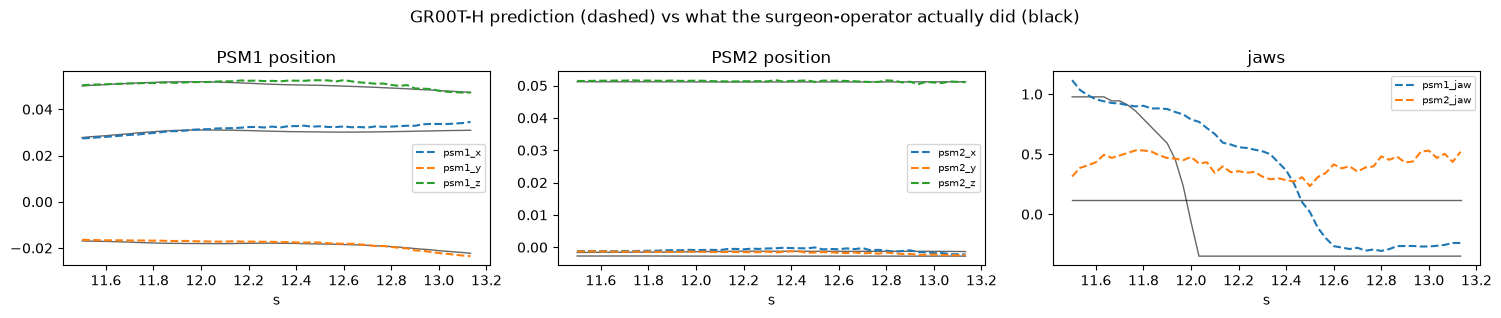

In [3]:
#@title GR00T-H inference { display-mode: "form" }
if BACKEND == "api":
    r = _post("/v1/groot/act", {"episode": EPISODE, "frame": FRAME})
else:
    r = BUNDLE["act"]
CHUNK = np.array(r["actions"])
print(f"instruction: {r['instruction']!r} | chunk {CHUNK.shape} | latency {r.get('latency_ms','cached')} ms | cached={r.get('cached')}")

t = np.arange(FRAME, FRAME + len(CHUNK)) / 30
fig, ax = plt.subplots(1, 3, figsize=(15, 3.2))
for j, (lab, dims) in enumerate([("PSM1 position", [0,1,2]), ("PSM2 position", [8,9,10]), ("jaws", [7,15])]):
    for d in dims:
        ax[j].plot(t, GT[FRAME:FRAME+len(CHUNK), d], "k-", lw=1, alpha=.6)
        ax[j].plot(t, CHUNK[:, d], "--", label=NAMES[d])
    ax[j].set_title(lab); ax[j].set_xlabel("s"); ax[j].legend(fontsize=7)
fig.suptitle("GR00T-H prediction (dashed) vs what the surgeon-operator actually did (black)"); plt.tight_layout()

## ▶ 3 · Open-loop evaluation, the same way NVIDIA does it (≈3 min)
We slide over the whole episode: every 50 steps, give GR00T-H the **real** observation, keep its 50-step chunk, and compare the stitched prediction with the recorded actions.
Metric = mean squared / absolute error over all 16 dimensions and all steps, exactly as in GR00T-H's official [`open_loop_eval.py`](https://github.com/NVIDIA-Medtech/GR00T-H/blob/main/gr00t/eval/open_loop_eval.py).
This is **open-loop**: errors never compound, because the model always sees the real scene. It says little about closed-loop success (see the Open-H report's discussion).
The **hold pose** row is a no-model reference (repeat the current pose for 50 steps). Surgical motion is slow, so it is a strong baseline over 1.7 s; beating it on the jaw, where the action is decisive, is harder than on position.


,MSE,MAE,MAE xyz (mm),MAE quat,MAE jaw (rad)
GR00T-H-N1.7,0.0076,0.0296,1.3748,0.0209,0.1490
hold pose (no model),0.0081,0.0167,1.1642,0.0173,0.0607


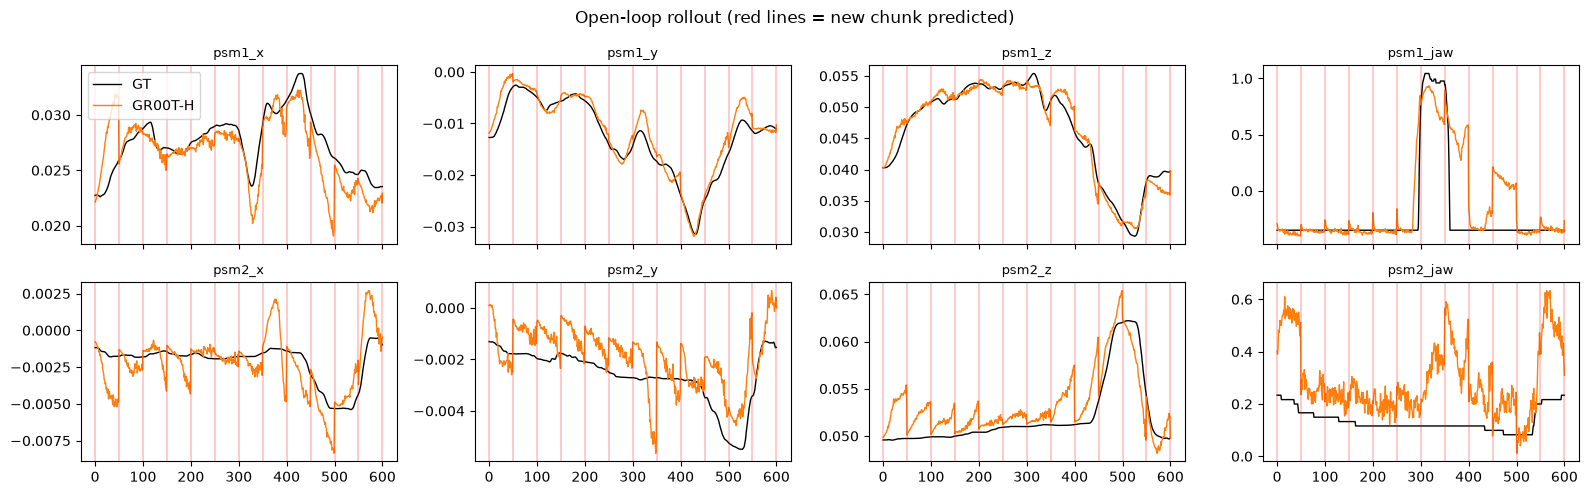

In [4]:
#@title Open-loop MSE / MAE (GR00T-H vs ACT) { display-mode: "form" }
ACT_PRED_URL = ""  #@param {type:"string"}
r = _post("/v1/groot/open_loop", {"episode": EPISODE, "start": 0, "steps": 10_000}, timeout=600) if BACKEND == "api" else BUNDLE["open_loop"]
gt, pred = np.array(r["gt"]), np.array(r["pred"])
GROUPS = {"xyz (mm)": [0, 1, 2, 8, 9, 10], "quat": [3, 4, 5, 6, 11, 12, 13, 14], "jaw (rad)": [7, 15]}
def ol_metrics(gt, pred):  # MSE/MAE == open_loop_eval.py; per-group MAE added for readability
    pred = np.array(pred, copy=True)
    for s in (slice(3, 7), slice(11, 15)):  # q and -q are the same rotation: align signs first
        pred[np.sum(gt[:, s] * pred[:, s], 1) < 0, s] *= -1
    m = {"MSE": float(np.mean((gt - pred) ** 2)), "MAE": float(np.mean(np.abs(gt - pred)))}
    for g, ix in GROUPS.items():
        m[f"MAE {g}"] = float(np.mean(np.abs(gt[:, ix] - pred[:, ix]))) * (1000 if "mm" in g else 1)
    return m
hold = gt[np.arange(len(gt)) // 50 * 50]   # "do nothing": repeat the pose at each chunk start
rows = {"GR00T-H-N1.7": ol_metrics(gt, pred), "hold pose (no model)": ol_metrics(gt, hold)}
if ACT_PRED_URL:   # (T,16) .npy from Segment 3, same episode, same 50-step protocol
    act = np.load(io.BytesIO(requests.get(ACT_PRED_URL).content))[: len(gt)]
    rows["ACT (Segment 3)"] = ol_metrics(gt[: len(act)], act)
display(pd.DataFrame(rows).T.style.format("{:.4f}"))

fig, ax = plt.subplots(2, 4, figsize=(16, 5), sharex=True)
for i, d in enumerate([0, 1, 2, 7, 8, 9, 10, 15]):
    a = ax.flat[i]; a.plot(gt[:, d], "k", lw=1, label="GT"); a.plot(pred[:, d], "C1", lw=1, label="GR00T-H")
    for s in range(0, len(gt), 50): a.axvline(s, color="r", lw=.3)
    a.set_title(NAMES[d], fontsize=9)
ax.flat[0].legend(); fig.suptitle("Open-loop rollout (red lines = new chunk predicted)"); plt.tight_layout()

## ▶ 4 · What would those actions *do*? Ask Cosmos-H-Dreams (≈3 min)
Cosmos-H-Dreams takes **one frame + a sequence of robot actions** and generates the video that should follow, 12 frames (~1.2 s) at a time.
We roll out 6 blocks (72 frames, ~7 s, the protocol of the Open-H report) twice from the same start frame:
1. with the **recorded actions** → any difference from the real video is *world-model error*;
2. with **GR00T-H's actions** → differences on top of that come from the *policy*.

Scoring = per-frame L1 and SSIM against the real video (Open-H report, Methods).

In [5]:
#@title Generate (or fetch) the two rollouts { display-mode: "form" }
BLOCKS = 6
def dream(source, actions=None, frame=None, episode=None, instruction=None):
    if BACKEND != "api":
        print("🔌 This cell generates a new video, so it needs the live server (BACKEND = 'api')."); return None
    j = {"episode": episode or EPISODE, "frame": FRAME if frame is None else frame,
         "action_source": source, "blocks": BLOCKS, "instruction": instruction}
    if actions is not None: j["actions"] = np.asarray(actions).tolist()
    job = _post("/v1/cosmos/dream", j)
    t0 = time.time()
    while job.get("status") not in ("done", "error"):
        time.sleep(3); job = {**_get(f"/v1/jobs/{job['job_id']}").json(), "job_id": job["job_id"]}
        print(f"\r{source}: {job['status']} ({time.time()-t0:.0f}s)", end="")
    if job["status"] == "error": raise RuntimeError(job.get("error"))
    path = f"dream_{source}_{job['job_id']}.mp4"; open(path, "wb").write(_get(job["video"]).content)
    print(f"\r{source}: done{' (cached)' if job.get('cached') else ''}            "); return path

if BACKEND == "api":
    DREAM = {s: dream(s) for s in ("gt", "groot")}
else:
    DREAM = {s: "bundle/" + p for s, p in BUNDLE["dreams"].items()}

def load_dream(p):
    fr = read_frames(p)
    return fr[1:] if len(fr) == BLOCKS * 12 + 1 else fr   # drop context frame if included
real = read_frames(vid, idx=set(range(FRAME + 3, FRAME + 3 * BLOCKS * 12 + 1, 3)))
gen = {k: load_dream(p) for k, p in DREAM.items()}
n = min(len(real), *map(len, gen.values()))
panel = np.concatenate([real[:n], gen["gt"][:n], gen["groot"][:n]], axis=2)
print("left: real video | middle: Cosmos + recorded actions | right: Cosmos + GR00T-H actions")
show_video(to_mp4(panel, "side_by_side.mp4"), width=960)

gt: done (cached)            
groot: done (cached)            


left: real video | middle: Cosmos + recorded actions | right: Cosmos + GR00T-H actions


,mean L1 ↓,mean SSIM ↑
recorded actions (world-model error),0.025,0.854
GR00T-H actions (+ policy error),0.042,0.773


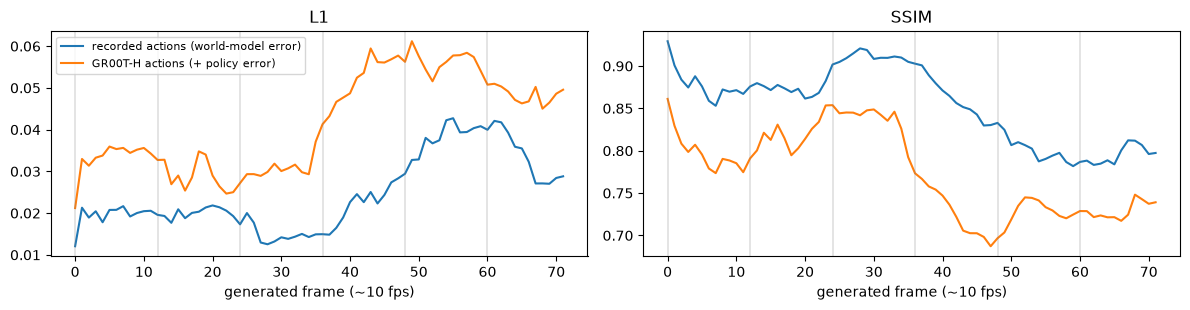

In [6]:
#@title Per-frame L1 / SSIM { display-mode: "form" }
from skimage.metrics import structural_similarity as ssim
def video_metrics(g, r):
    g, r = g.astype(np.float32) / 255, r.astype(np.float32) / 255
    l1 = np.abs(g - r).mean(axis=(1, 2, 3))
    s = np.array([ssim(a, b, channel_axis=-1, data_range=1.0) for a, b in zip(g, r)])
    return l1, s
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2)); summary = {}
for k, lab in [("gt", "recorded actions (world-model error)"), ("groot", "GR00T-H actions (+ policy error)")]:
    l1, s = video_metrics(gen[k][:n], real[:n]); summary[lab] = {"mean L1 ↓": l1.mean(), "mean SSIM ↑": s.mean()}
    ax[0].plot(l1, label=lab); ax[1].plot(s, label=lab)
for a, t in zip(ax, ["L1", "SSIM"]):
    a.set_title(t); a.set_xlabel("generated frame (~10 fps)"); [a.axvline(b * 12, color="gray", lw=.3) for b in range(BLOCKS)]
ax[0].legend(fontsize=8); plt.tight_layout(); display(pd.DataFrame(summary).T.style.format("{:.3f}"))

## ▶ 5 · Takeaways (≈1.5 min)
- **Pretraining helps** — in the Open-H report, GR00T-H matched ACT with 1/3 of the SutureBot data and was the only policy to complete end-to-end suturing (25 %).
- **Open-loop error is not task success.** Low MSE can still fail on the robot; small errors compound once the policy sees its own consequences.
- **World models let us *look* at a policy's actions without a robot**, but they have their own error. Always roll out recorded actions as a reference.
- **Next steps:** closed-loop evaluation inside the world model (the policy sees generated frames), simulation in [ORBIT-Surgical](https://orbit-surgical.github.io/), and fine-tuning GR00T-H on your own embodiment ([GR00T-H repo](https://github.com/NVIDIA-Medtech/GR00T-H)).
- **Run it yourself afterwards:** the same server is a one-click Brev Launchable (link on the tutorial website).

📄 Open-H-Embodiment consortium, *Open-H-Embodiment* report ([arXiv:2604.21017](https://arxiv.org/abs/2604.21017)).

---
# 🧪 Explore on your own
Each cell below stands alone (it only needs Setup and the clip above). Collapse this section during the live walkthrough.
Requests that are not pre-computed run live on the shared GPU and wait in a queue, so be patient with Cosmos jobs (~1 min each).

### 🧪 A · Change the instruction: does language steer the policy?

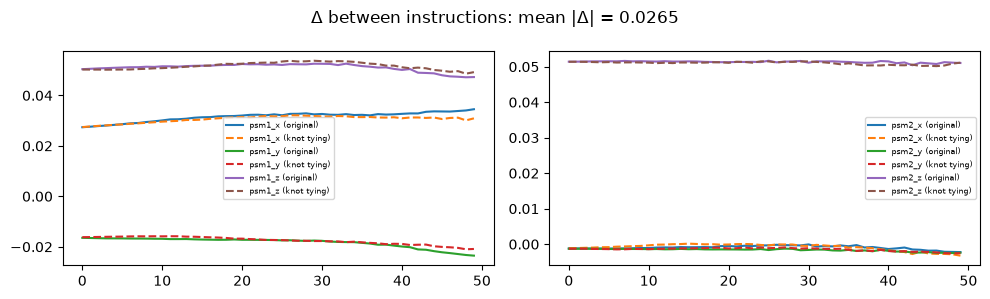

In [7]:
#@title Same frame, different instruction { display-mode: "form" }
INSTRUCTION = "knot tying"  #@param ["needle pickup", "needle throw", "knot tying"]
if BACKEND == "cache":
    alt = BUNDLE["act_alt"].get(INSTRUCTION) or print("not in cache; needs the API")
else:
    alt = _post("/v1/groot/act", {"episode": EPISODE, "frame": FRAME, "instruction": INSTRUCTION})
if alt:
    A = np.array(alt["actions"])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    for j, d in enumerate([[0, 1, 2], [8, 9, 10]]):
        for k in d:
            ax[j].plot(CHUNK[:, k], "-", label=f"{NAMES[k]} (original)"); ax[j].plot(A[:, k], "--", label=f"{NAMES[k]} ({INSTRUCTION})")
        ax[j].legend(fontsize=6)
    plt.suptitle(f"Δ between instructions: mean |Δ| = {np.abs(A - CHUNK).mean():.4f}"); plt.tight_layout()

### 🧪 B · Dream the instruction-steered actions

In [8]:
#@title Cosmos rollout of a different instruction (live) { display-mode: "form" }
INSTRUCTION_B = "knot tying"  #@param ["needle pickup", "needle throw", "knot tying"]
p = dream("groot", instruction=INSTRUCTION_B)
show_video(p)

groot: done (cached)            


### 🧪 C · Break the actions on purpose: is the world model paying attention?

In [9]:
#@title Perturb recorded actions and dream them (live) { display-mode: "form" }
PERTURBATION = "freeze PSM1"  #@param ["freeze PSM1", "open both jaws", "double the motion", "swap arms"]
n_raw = BLOCKS * 36 + 1
a = GT[FRAME:FRAME + n_raw].copy()
if PERTURBATION == "freeze PSM1":       a[:, 0:8] = a[0, 0:8]
elif PERTURBATION == "open both jaws":  a[:, [7, 15]] = GT[:, [7, 15]].max(0)
elif PERTURBATION == "double the motion":
    a[:, [0,1,2,8,9,10]] = a[0, [0,1,2,8,9,10]] + 2 * (a[:, [0,1,2,8,9,10]] - a[0, [0,1,2,8,9,10]])
elif PERTURBATION == "swap arms":       a = np.concatenate([a[:, 8:], a[:, :8]], 1)
show_video(dream("custom", actions=a))

custom: done (cached)            


### 🧪 D · Another episode

In [10]:
#@title Pick any episode hosted on the server { display-mode: "form" }
if BACKEND == "api":
    eps = _get("/v1/episodes").json(); print(eps["episodes"], eps.get("meta", ""))
OTHER_EPISODE = 0  #@param {type:"integer"}
OTHER_FRAME = 0    #@param {type:"integer"}
if OTHER_EPISODE:
    r = _post("/v1/groot/open_loop", {"episode": OTHER_EPISODE, "start": OTHER_FRAME, "steps": 300}, timeout=600)
    print("open-loop:", r["metrics"])

[1441, 1442, 1443, 1444, 1445, 1446, 1447, 1448, 1449, 1450, 1451] {}


### 🧪 E · Bring your own policy (e.g. your ACT from Segment 3)

In [11]:
#@title Dream any (T,16) absolute action array @30 Hz { display-mode: "form" }
MY_ACTIONS_NPY = ""  #@param {type:"string"}
# a local path or a URL; left empty, this dreams ACT's predictions from section 3 (ACT_PRED_URL)
src = MY_ACTIONS_NPY or ACT_PRED_URL
if src:
    mine = np.load(io.BytesIO(requests.get(src).content)) if src.startswith("http") else np.load(src)
    print("open-loop vs GT:", ol_metrics(GT[:len(mine)], mine))
    show_video(dream("custom", actions=mine[FRAME:FRAME + BLOCKS * 36 + 1]))

### 🧪 F · Homework: closed loop inside the world model
Feed Cosmos' generated frame back to the policy and repeat. Cosmos only renders the endoscope view, so use GR00T-H's endoscope-only embodiment (`jhu_imerse_dvrk_mono`) or a policy trained on the endoscope alone. This is how NVIDIA screened GR00T-H checkpoints (Cosmos-Surg-dVRK). Deploy the Launchable and try it.